# Monte Carlo and Q-learning on a Grid Maze in Python, Line by Line

**Reinforcement Lab · CSIT843A Lecture 5** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/reinforcementlearning/code-qlearning.html**

A complete, runnable notebook that builds a small maze as an environment, samples random episodes, computes returns, and learns a Q-table with Monte Carlo and with Q-learning. Then both methods are compared on the big maze. Only NumPy and Matplotlib are needed. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. Write a grid maze as an environment with reset() and step()
2. Sample random episodes and compute returns backwards
3. Implement Monte Carlo control with an ε-greedy policy
4. Implement Q-learning in a dozen lines
5. Compare learning curves and read the learned policy

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

**NumPy** for arrays and random numbers, **Matplotlib** for charts. Nothing else: every algorithm is written out by hand.

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy: arrays, maths and random numbers. `np` is the standard nickname.
3. `import matplotlib.pyplot as plt`  
   Matplotlib's plotting interface, used for every chart.
4. `plt.rcParams["figure.figsize"] = (7, 4)`  
   Default figure size (width, height) in inches.
5. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
6. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.

## 2. The maze as an environment

An environment only needs two functions. `reset()` starts an episode and returns the first state. `step(action)` applies an action and returns **the next state, the reward, and whether the episode is over**. The agent will see nothing else.

States are `(column, row)` with row 1 at the bottom. Actions: 0 up, 1 down, 2 left, 3 right.

In [2]:
class Maze:
    MOVES = {0: (0, 1), 1: (0, -1), 2: (-1, 0), 3: (1, 0)}

    def __init__(self, width, height, walls, start, target, max_steps):
        self.width, self.height = width, height
        self.walls, self.start, self.target = set(walls), start, target
        self.max_steps = max_steps

    def reset(self):
        self.state, self.t = self.start, 0
        return self.state

    def step(self, action):
        dc, dr = self.MOVES[action]
        nxt = (self.state[0] + dc, self.state[1] + dr)
        inside = 1 <= nxt[0] <= self.width and 1 <= nxt[1] <= self.height
        if inside and nxt not in self.walls:
            self.state = nxt
        self.t += 1
        reached = self.state == self.target
        reward = 0.0 if reached else -1.0
        done = reached or self.t >= self.max_steps
        return self.state, reward, done

small = Maze(7, 5, walls=[(2, 4), (4, 4), (5, 4), (6, 4), (2, 3), (6, 3), (1, 2), (2, 2), (4, 2), (6, 2), (4, 1)],
             start=(1, 1), target=(7, 5), max_steps=40)
big = Maze(11, 7, walls=[(10, 7), (2, 6), (3, 6), (4, 6), (6, 6), (7, 6), (8, 6), (10, 6), (2, 5), (6, 5), (8, 5), (1, 4), (2, 4), (4, 4),
                         (5, 4), (6, 4), (8, 4), (10, 4), (8, 3), (2, 2), (3, 2), (4, 2), (6, 2), (8, 2), (9, 2), (10, 2), (2, 1)],
           start=(1, 1), target=(11, 7), max_steps=60)
print("small maze:", small.width, "x", small.height, " big maze:", big.width, "x", big.height)

small maze: 7 x 5  big maze: 11 x 7


**Line by line**

1. `class Maze:`  
   A class bundles the maze's data (size, walls) with its two functions.
2. `MOVES = {0: (0, 1), 1: (0, -1), 2: (-1, 0), 3: (1, 0)}`  
   How each action changes (column, row): up, down, left, right.
3. `def __init__(self, width, height, walls, start, target, max_steps):` …  
   Store the layout of one maze.
4. `self.max_steps = max_steps`  
   Episodes are cut off after this many steps.
5. `def reset(self):` …  
   Start a new episode: put the agent on the start square.
6. `def step(self, action):`  
   One time step of the MDP.
7. `dc, dr = self.MOVES[action]`  
   The change in column and row for this action.
8. `nxt = (self.state[0] + dc, self.state[1] + dr)`  
   Where the agent would end up.
9. `inside = 1 <= nxt[0] <= self.width and 1 <= nxt[1] <= self.height`  
   Still on the grid?
10. `if inside and nxt not in self.walls:` …  
   A move into a wall or off the grid leaves the agent where it is.
11. `self.t += 1`  
   Count the step.
12. `reached = self.state == self.target`  
   Did we enter the goal square?
13. `reward = 0.0 if reached else -1.0`  
   0 for reaching the target, −1 for every other step.
14. `done = reached or self.t >= self.max_steps`  
   The episode ends at the target or at the time limit.
15. `return self.state, reward, done`  
   Exactly what the agent receives.
16. `small = Maze(7, 5, walls=[(2, 4), (4, 4), (5, 4), (6, 4), (2, 3), (6, 3), (1, 2), (2, 2), (4, 2), (6, 2), (4, 1)],` …  
   The small maze: corridors one square wide, shortest route 10 moves.
17. `big = Maze(11, 7, walls=[(10, 7), (2, 6), (3, 6), (4, 6), (6, 6), (7, 6), (8, 6), (10, 6), (2, 5), (6, 5), (8, 5), (1, 4), (2, 4), (4, 4),` …  
   The big maze: shortest route 20 moves.
18. `print("small maze:", small.width, "x", small.height, " big maze:", big.width, "x", big.height)`  
   A quick check.

## 3. Random actions and trajectories

With no knowledge, the agent can only pick actions at random. We record each **trajectory** (state, action, reward, …) and count how often the agent reaches the goal by luck.

reached the goal in 31 of 2000 episodes (1.6%)


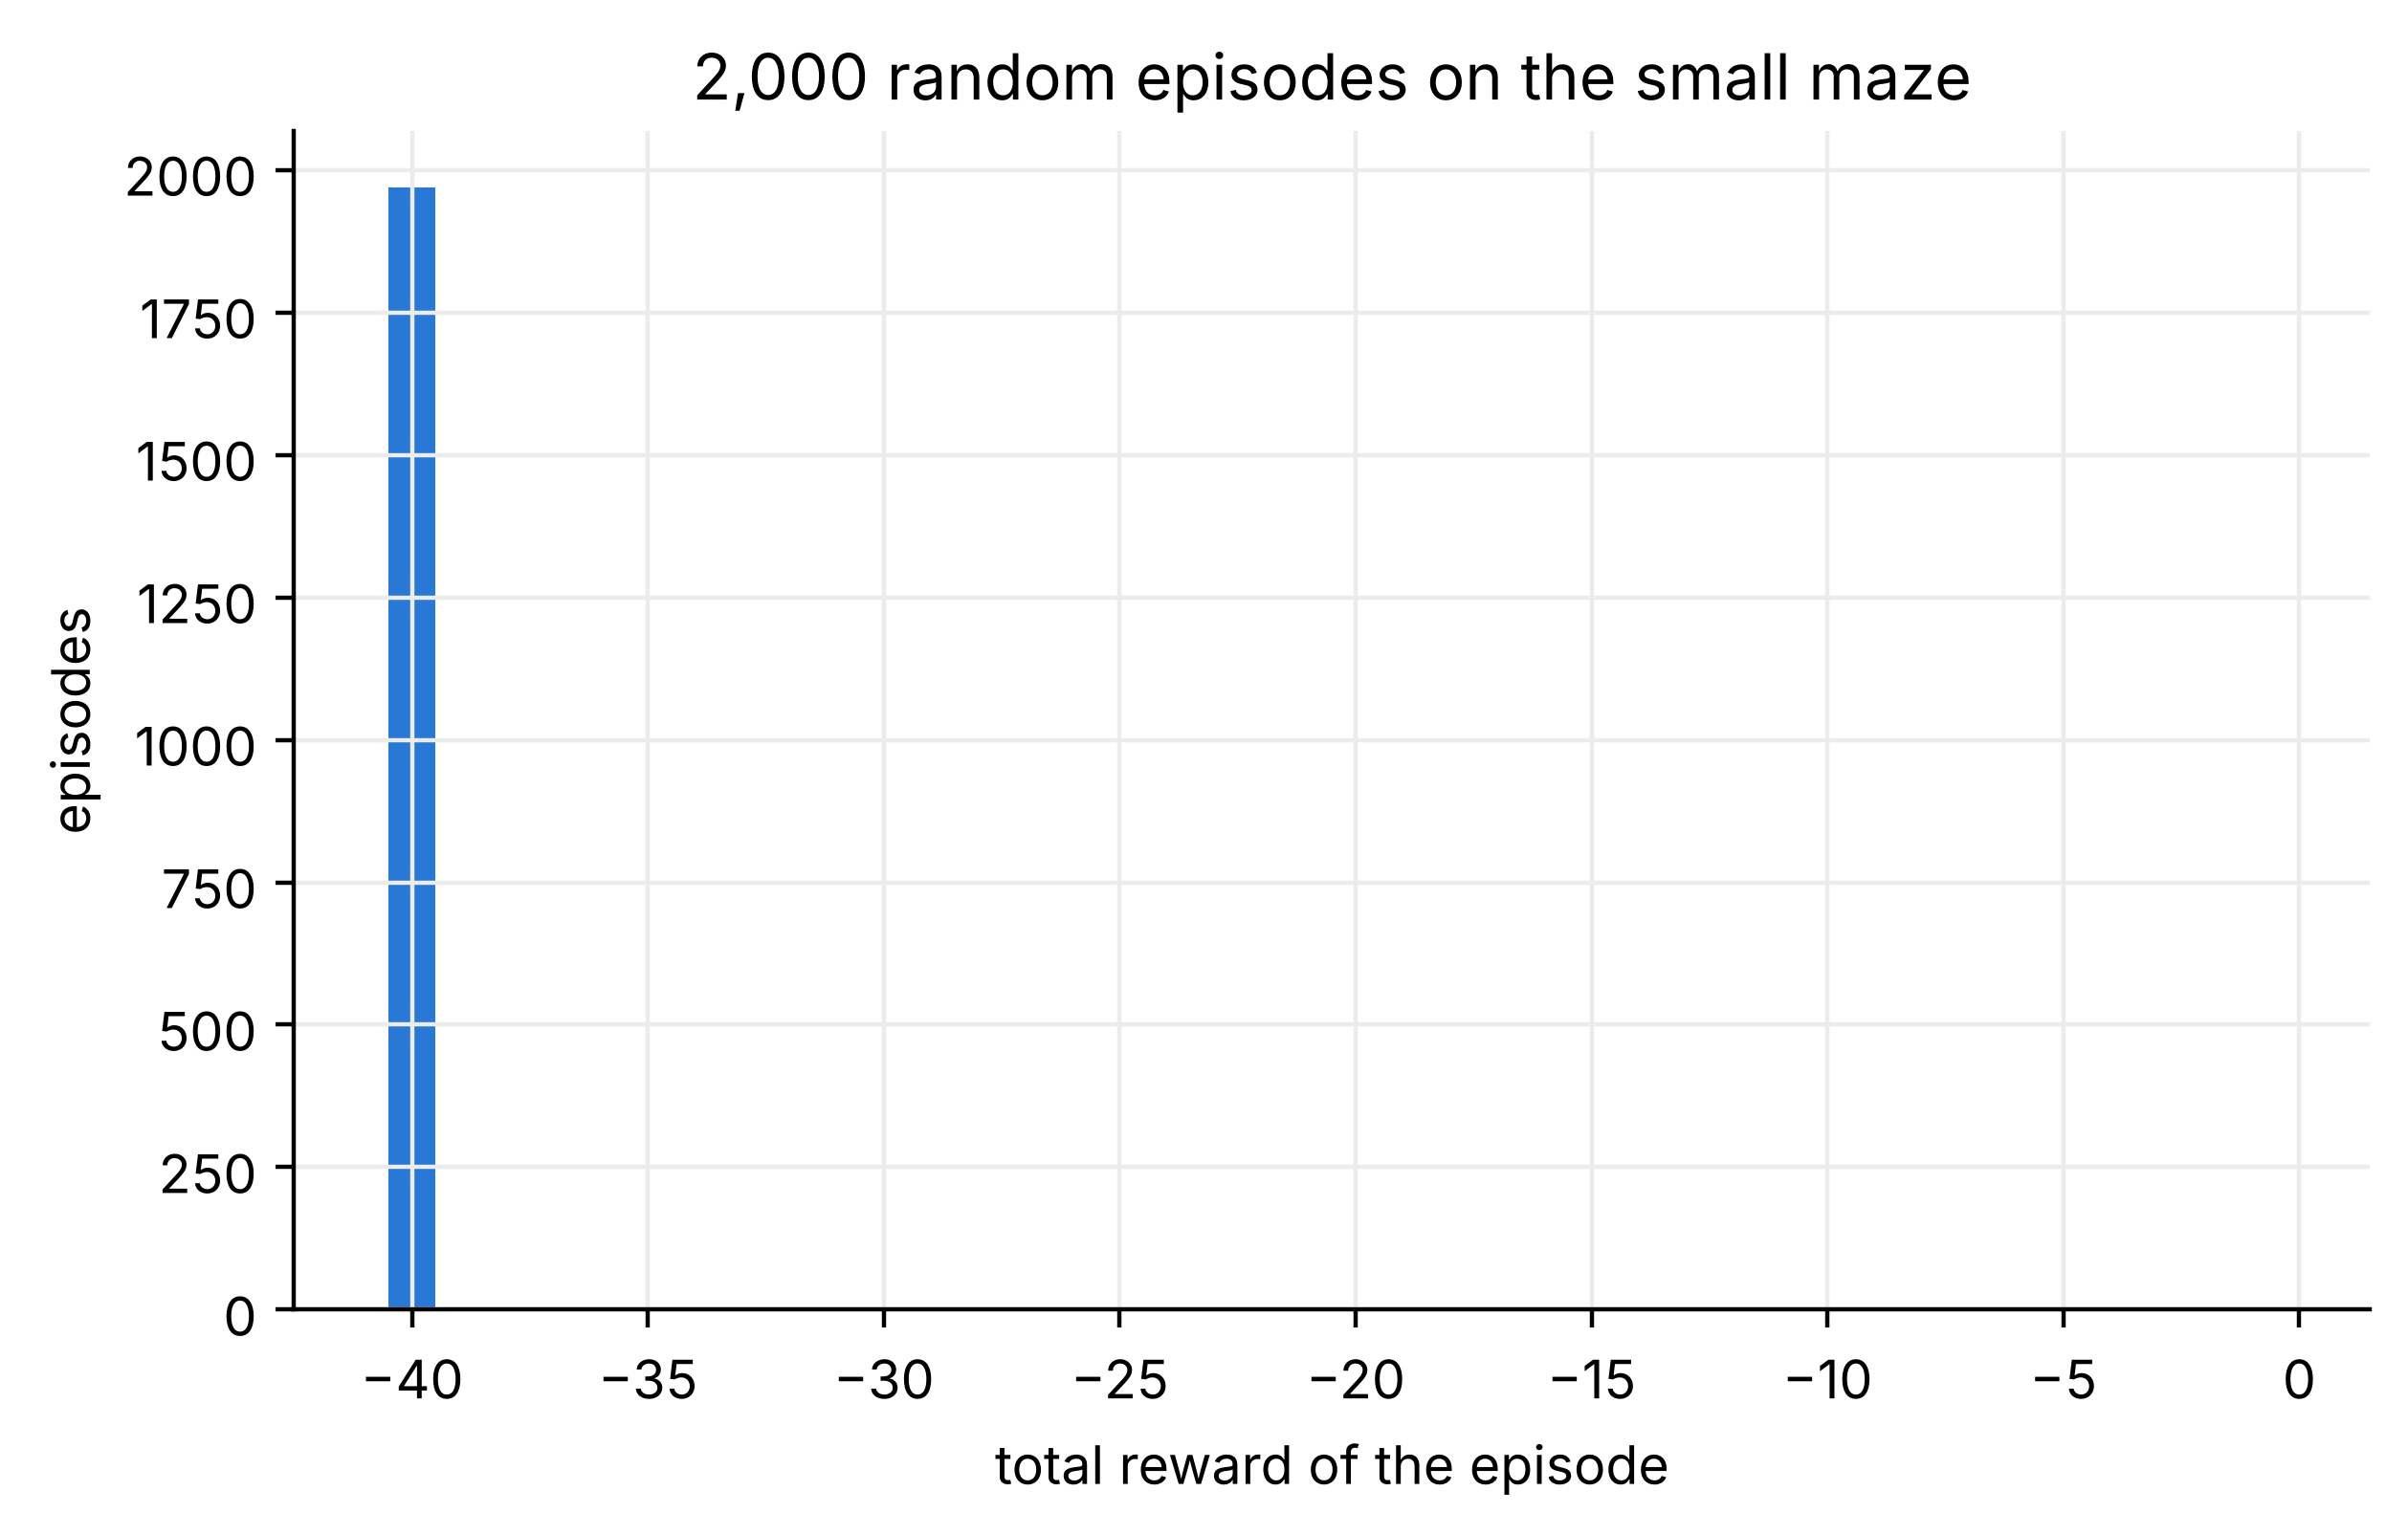

In [3]:
rng = np.random.default_rng(0)

def run_random_episode(env):
    s, trajectory, done = env.reset(), [], False
    while not done:
        a = rng.integers(4)
        s2, r, done = env.step(a)
        trajectory.append((s, a, r))
        s = s2
    return trajectory

episodes = [run_random_episode(small) for _ in range(2000)]
totals = [sum(r for _, _, r in ep) for ep in episodes]
reached = sum(1 for ep in episodes if ep[-1][2] == 0)
print(f"reached the goal in {reached} of 2000 episodes ({reached / 20:.1f}%)")

plt.hist(totals, bins=np.arange(-40.5, 0, 1), color="#2a78d6")
plt.xlabel("total reward of the episode"); plt.ylabel("episodes")
plt.title("2,000 random episodes on the small maze")
plt.show()

**Line by line**

1. `rng = np.random.default_rng(0)`  
   A random-number generator with a fixed seed, so the results are repeatable.
2. `def run_random_episode(env):`  
   Play one episode with random actions and record it.
3. `s, trajectory, done = env.reset(), [], False`  
   Start, and an empty list for the trajectory.
4. `while not done:`  
   Until the target or the time limit.
5. `a = rng.integers(4)`  
   A random action 0–3: every action has probability ¼.
6. `s2, r, done = env.step(a)`  
   Ask the environment what happens.
7. `trajectory.append((s, a, r))`  
   Write it down: this is sampling.
8. `s = s2` …  
   Move on.
9. `episodes = [run_random_episode(small) for _ in range(2000)]`  
   Sample 2,000 random episodes.
10. `totals = [sum(r for _, _, r in ep) for ep in episodes]`  
   The total reward of each episode.
11. `reached = sum(1 for ep in episodes if ep[-1][2] == 0)`  
   Episodes that ended at the goal (reward 0 on the last step).
12. `print(f"reached the goal in {reached} of 2000 episodes ({reached / 20:.1f}%)")`  
   Only a few percent: luck.
13. `plt.hist(totals, bins=np.arange(-40.5, 0, 1), color="#2a78d6")`  
   How the total rewards are spread.
14. `plt.xlabel("total reward of the episode"); plt.ylabel("episodes")` …  
   Axis labels.
15. `plt.show()`  
   Most episodes are cut off at −40.

## 4. Returns, computed backwards

With $G_t = R_{t+1} + \gamma\, G_{t+1}$, the return of every step is easiest to compute from the **end**. Here is a lucky trajectory.

In [4]:
def returns(rewards, gamma):
    G, out = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G
        out.append(G)
    return out[::-1]

lucky = next(ep for ep in episodes if ep[-1][2] == 0)
G = returns([r for _, _, r in lucky], gamma=0.8)
for t, ((s, a, r), g) in enumerate(zip(lucky, G)):
    print(f"t={t:2d}  state={s}  action={'↑↓←→'[a]}  R={r:4.0f}  G={g:6.2f}")

t= 0  state=(1, 1)  action=→  R=  -1  G= -5.00
t= 1  state=(2, 1)  action=→  R=  -1  G= -4.99
t= 2  state=(3, 1)  action=↓  R=  -1  G= -4.99
t= 3  state=(3, 1)  action=↓  R=  -1  G= -4.99
t= 4  state=(3, 1)  action=↓  R=  -1  G= -4.99
t= 5  state=(3, 1)  action=←  R=  -1  G= -4.98
t= 6  state=(2, 1)  action=↑  R=  -1  G= -4.98
t= 7  state=(2, 1)  action=→  R=  -1  G= -4.98
t= 8  state=(3, 1)  action=↑  R=  -1  G= -4.97
t= 9  state=(3, 2)  action=↓  R=  -1  G= -4.96
t=10  state=(3, 1)  action=↓  R=  -1  G= -4.95
t=11  state=(3, 1)  action=←  R=  -1  G= -4.94
t=12  state=(2, 1)  action=←  R=  -1  G= -4.93
t=13  state=(1, 1)  action=←  R=  -1  G= -4.91
t=14  state=(1, 1)  action=→  R=  -1  G= -4.89
t=15  state=(2, 1)  action=→  R=  -1  G= -4.86
t=16  state=(3, 1)  action=↑  R=  -1  G= -4.82
t=17  state=(3, 2)  action=↑  R=  -1  G= -4.78
t=18  state=(3, 3)  action=↑  R=  -1  G= -4.73
t=19  state=(3, 4)  action=←  R=  -1  G= -4.66
t=20  state=(3, 4)  action=→  R=  -1  G= -4.57
t=21  state=(

**Line by line**

1. `def returns(rewards, gamma):`  
   Return of every step of one episode.
2. `G, out = 0.0, []`  
   After the last step nothing follows: start with G = 0.
3. `for r in reversed(rewards):`  
   Walk backwards through the rewards.
4. `G = r + gamma * G` …  
   G_t = R_{t+1} + γ G_{t+1}
5. `return out[::-1]`  
   Put them back in time order.
6. `lucky = next(ep for ep in episodes if ep[-1][2] == 0)`  
   The first random episode that reached the goal.
7. `G = returns([r for _, _, r in lucky], gamma=0.8)`  
   Its returns with γ = 0.8.
8. `for t, ((s, a, r), g) in enumerate(zip(lucky, G)):`  
   Print one row per step.
9. `print(f"t={t:2d}  state={s}  action={'↑↓←→'[a]}  R={r:4.0f}  G={g:6.2f}")`  
   Even a successful episode has negative returns.

## 5. ε-greedy and Monte Carlo control

The Q-table has one entry per square and action. **ε-greedy**: with probability ε pick a random action, otherwise the action with the highest Q. **Monte Carlo control** plays a whole episode, then moves every visited entry a step α towards its return. ε falls from 0.9 to 0.1.

In [5]:
def epsilon_greedy(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(4))
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max())))

def monte_carlo(env, episodes=300, alpha=0.1, gamma=0.8, seed=0):
    rng = np.random.default_rng(seed)
    Q = {(c, r): np.zeros(4) for c in range(1, env.width + 1) for r in range(1, env.height + 1)}
    curve = []
    for ep in range(episodes):
        eps = 0.9 - 0.8 * ep / (episodes - 1)
        s, done, traj = env.reset(), False, []
        while not done:
            a = epsilon_greedy(Q, s, eps, rng)
            s2, r, done = env.step(a)
            traj.append((s, a, r)); s = s2
        G = 0.0
        for s, a, r in reversed(traj):
            G = r + gamma * G
            Q[s][a] += alpha * (G - Q[s][a])
        curve.append(sum(r for _, _, r in traj))
    return Q, curve

**Line by line**

1. `def epsilon_greedy(Q, s, eps, rng):`  
   Choose an action for state s.
2. `if rng.random() < eps:`  
   With probability ε…
3. `return int(rng.integers(4))`  
   …explore: a random action.
4. `q = Q[s]`  
   Otherwise exploit: the four values of this square.
5. `return int(rng.choice(np.flatnonzero(q == q.max())))`  
   The best action (ties broken at random).
6. `def monte_carlo(env, episodes=300, alpha=0.1, gamma=0.8, seed=0):`  
   Monte Carlo control.
7. `rng = np.random.default_rng(seed)`  
   Each run gets its own random numbers.
8. `Q = {(c, r): np.zeros(4) for c in range(1, env.width + 1) for r in range(1, env.height + 1)}`  
   All entries 0 at the start.
9. `curve = []`  
   Total reward of every episode, to plot later.
10. `for ep in range(episodes):`  
   One iteration = one complete episode.
11. `eps = 0.9 - 0.8 * ep / (episodes - 1)` …  
   ε decreases linearly from 0.9 to 0.1.
12. `while not done:` …  
   Generate the episode first…
13. `G = 0.0` …  
   …then update, going backwards.
14. `G = r + gamma * G`  
   The return from this step.
15. `Q[s][a] += alpha * (G - Q[s][a])`  
   Move the entry 10% of the way towards the return.
16. `curve.append(sum(r for _, _, r in traj))` …  
   Record how well this episode went.

## 6. Q-learning

Q-learning updates after **every step**, towards one reward plus the best value of the next square: $Q(S,A) \leftarrow Q(S,A) + \alpha\,[R + \gamma \max_a Q(S',a) - Q(S,A)]$. At the target there is no next square, so it counts as 0: the anchor.

In [6]:
def q_learning(env, episodes=300, alpha=0.1, gamma=0.8, seed=0):
    rng = np.random.default_rng(seed)
    Q = {(c, r): np.zeros(4) for c in range(1, env.width + 1) for r in range(1, env.height + 1)}
    curve = []
    for ep in range(episodes):
        eps = 0.9 - 0.8 * ep / (episodes - 1)
        s, done, total = env.reset(), False, 0.0
        while not done:
            a = epsilon_greedy(Q, s, eps, rng)
            s2, r, done = env.step(a)
            at_target = s2 == env.target
            target = r + (0.0 if at_target else gamma * Q[s2].max())
            Q[s][a] += alpha * (target - Q[s][a])
            s, total = s2, total + r
        curve.append(total)
    return Q, curve

**Line by line**

1. `def q_learning(env, episodes=300, alpha=0.1, gamma=0.8, seed=0):` …  
   Q-learning.
2. `Q = {(c, r): np.zeros(4) for c in range(1, env.width + 1) for r in range(1, env.height + 1)}` …  
   The same table of zeros.
3. `eps = 0.9 - 0.8 * ep / (episodes - 1)` …  
   The same ε schedule as Monte Carlo, for a fair race.
4. `a = epsilon_greedy(Q, s, eps, rng)`  
   Explore or exploit.
5. `s2, r, done = env.step(a)`  
   One step of experience.
6. `at_target = s2 == env.target`  
   At the goal, the next square's value is 0.
7. `target = r + (0.0 if at_target else gamma * Q[s2].max())`  
   The TD target: one reward + γ × best next value.
8. `Q[s][a] += alpha * (target - Q[s][a])` …  
   The Q-learning update: no waiting for the end.

## 7. The race on the small maze

Average 50 runs of each method, because one run proves little.

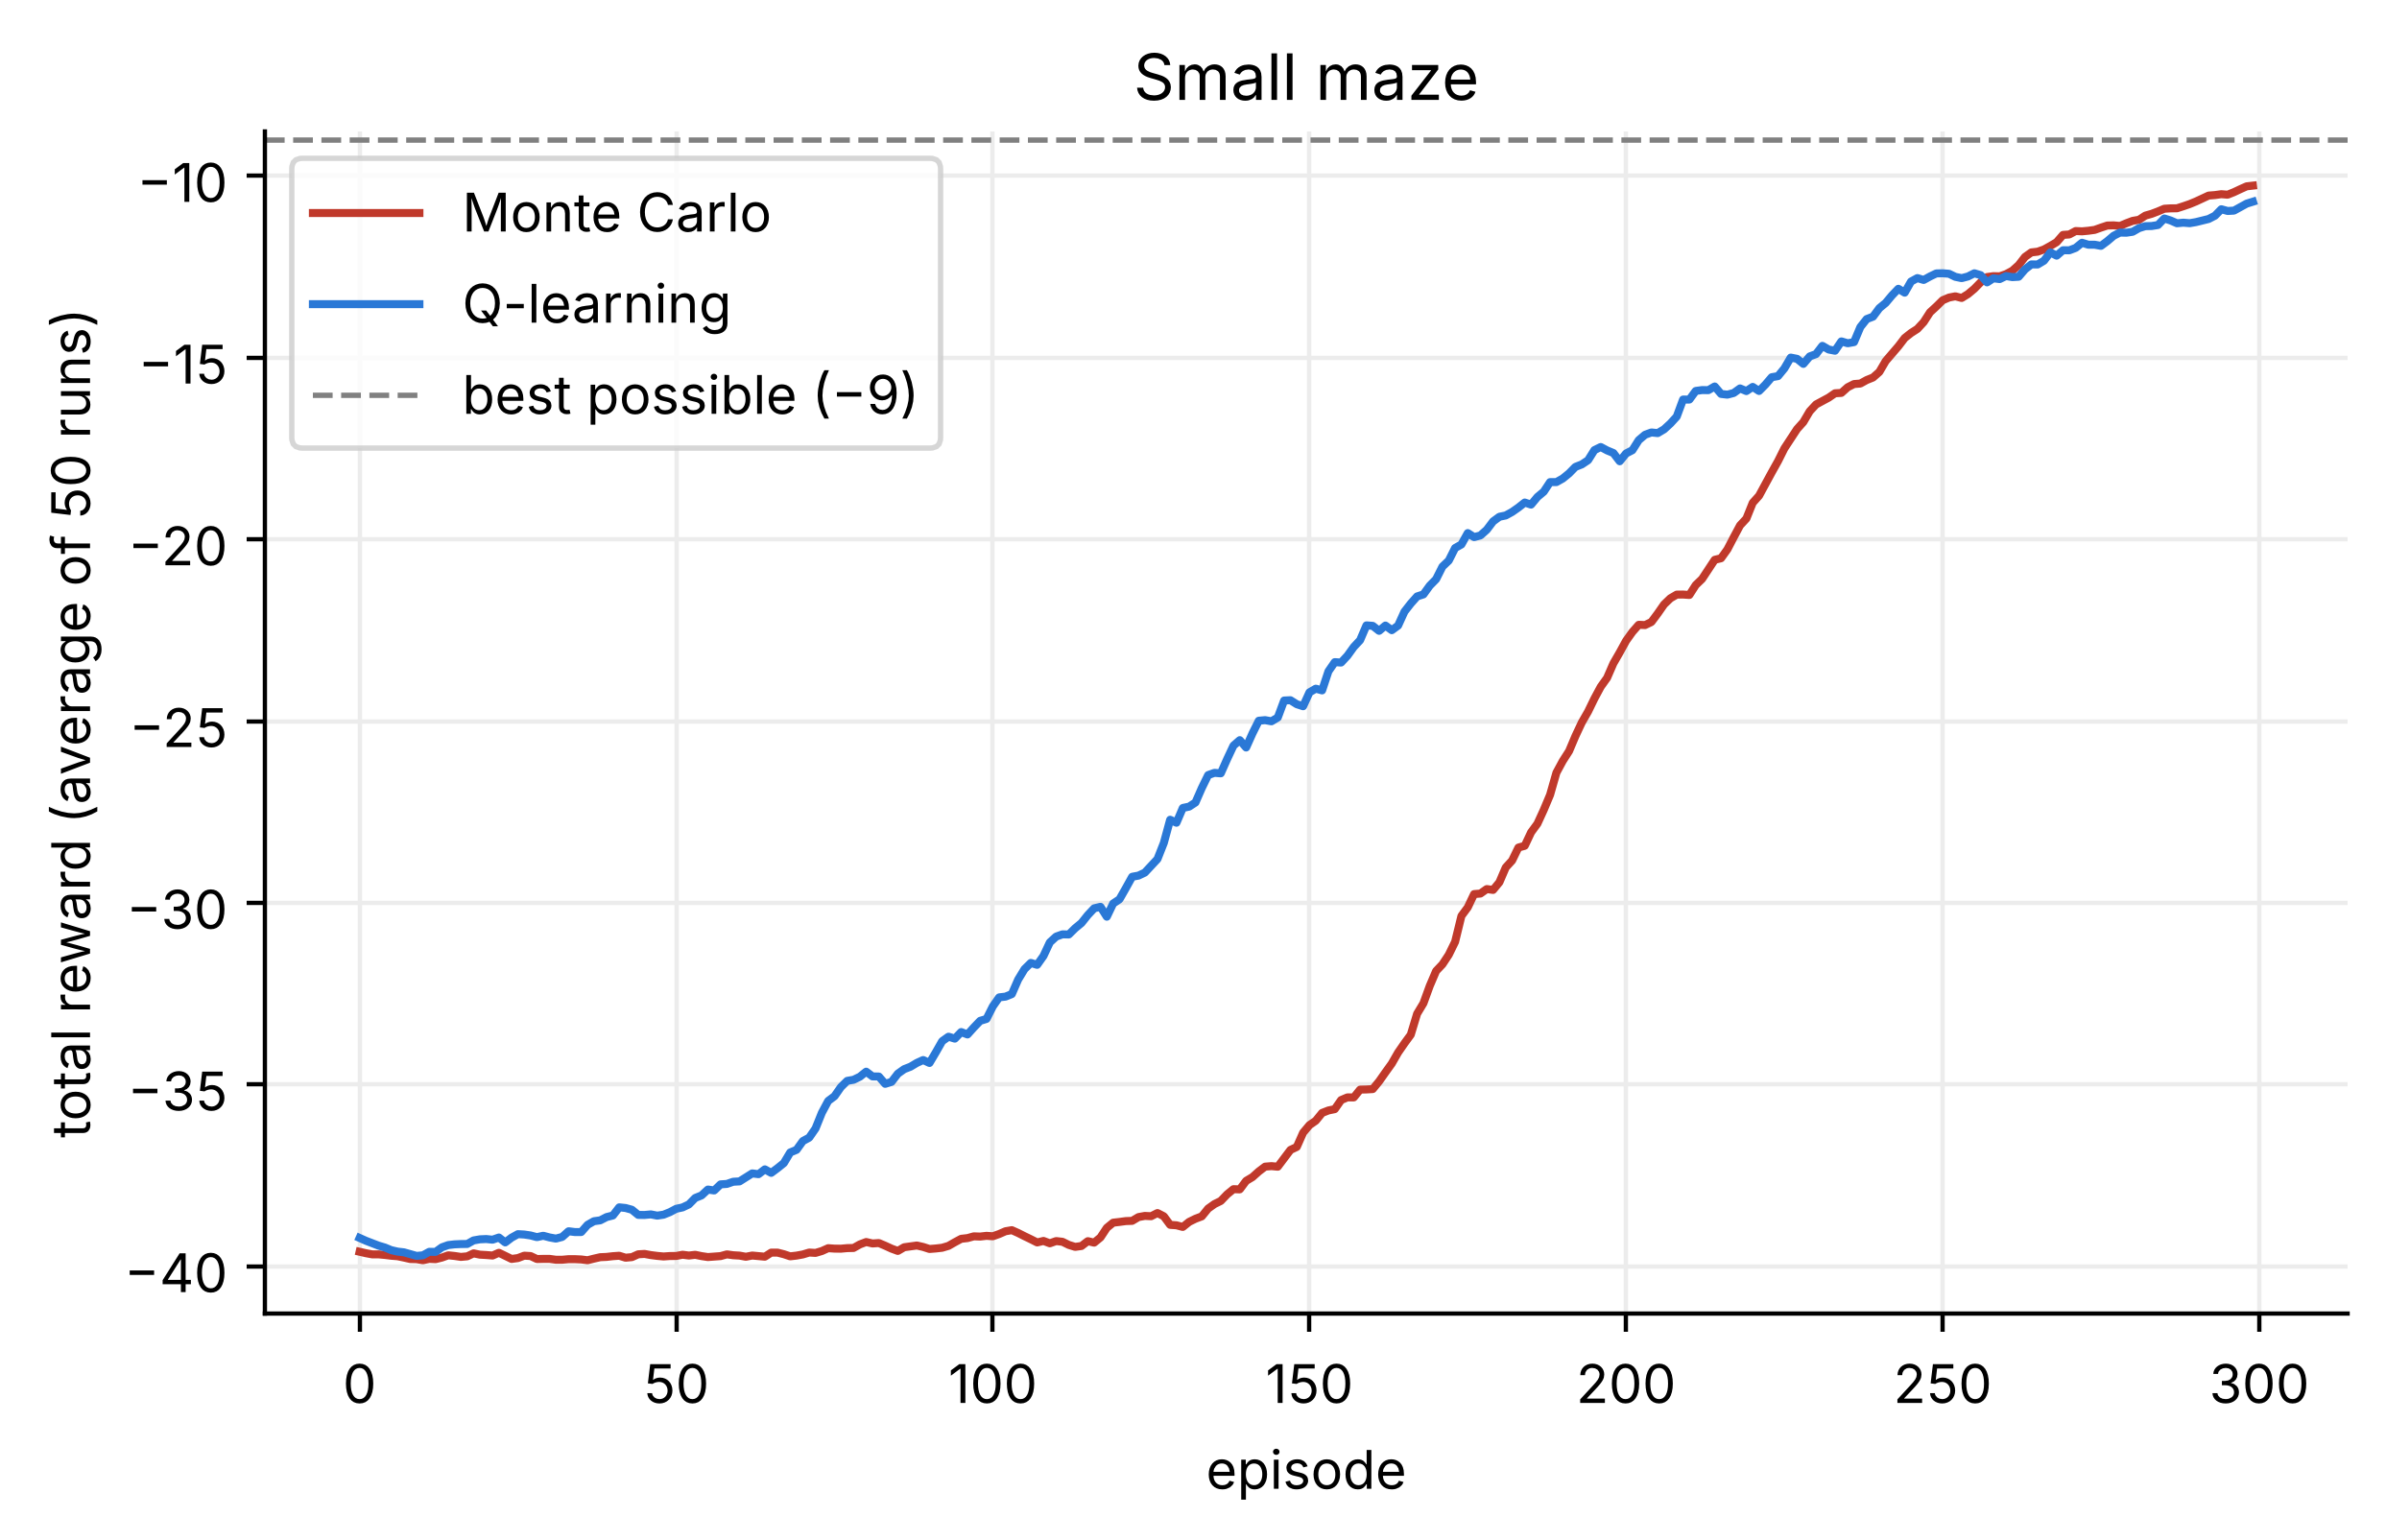

last 50 episodes: Monte Carlo -11.34, Q-learning -11.69


In [7]:
def average_curve(method, env, runs=50, episodes=300):
    return np.mean([method(env, episodes=episodes, seed=k)[1] for k in range(runs)], axis=0)

def smooth(x, k=10):
    return np.convolve(np.pad(x, (k - 1, 0), mode="edge"), np.ones(k) / k, mode="valid")

mc = average_curve(monte_carlo, small)
ql = average_curve(q_learning, small)
plt.plot(smooth(mc), color="#c0392b", label="Monte Carlo")
plt.plot(smooth(ql), color="#2a78d6", label="Q-learning")
plt.axhline(-9, ls="--", color="grey", lw=1, label="best possible (−9)")
plt.xlabel("episode"); plt.ylabel("total reward (average of 50 runs)"); plt.legend()
plt.title("Small maze")
plt.show()
print(f"last 50 episodes: Monte Carlo {mc[-50:].mean():.2f}, Q-learning {ql[-50:].mean():.2f}")

**Line by line**

1. `def average_curve(method, env, runs=50, episodes=300):` …  
   Run a method many times and average the learning curves.
2. `def smooth(x, k=10):` …  
   A running average to make the curves readable.
3. `mc = average_curve(monte_carlo, small)`  
   50 runs of Monte Carlo.
4. `ql = average_curve(q_learning, small)`  
   50 runs of Q-learning.
5. `plt.plot(smooth(mc), color="#c0392b", label="Monte Carlo")`  
   Red: Monte Carlo.
6. `plt.plot(smooth(ql), color="#2a78d6", label="Q-learning")`  
   Blue: Q-learning.
7. `plt.axhline(-9, ls="--", color="grey", lw=1, label="best possible (−9)")` …  
   10 moves: nine −1 and one 0.
8. `print(f"last 50 episodes: Monte Carlo {mc[-50:].mean():.2f}, Q-learning {ql[-50:].mean():.2f}")`  
   On the small maze both end up close to the best (−9). The big maze shows the real difference.

## 8. What did it learn?

Draw the maze and, in every square, the action with the highest Q: the **greedy policy**.

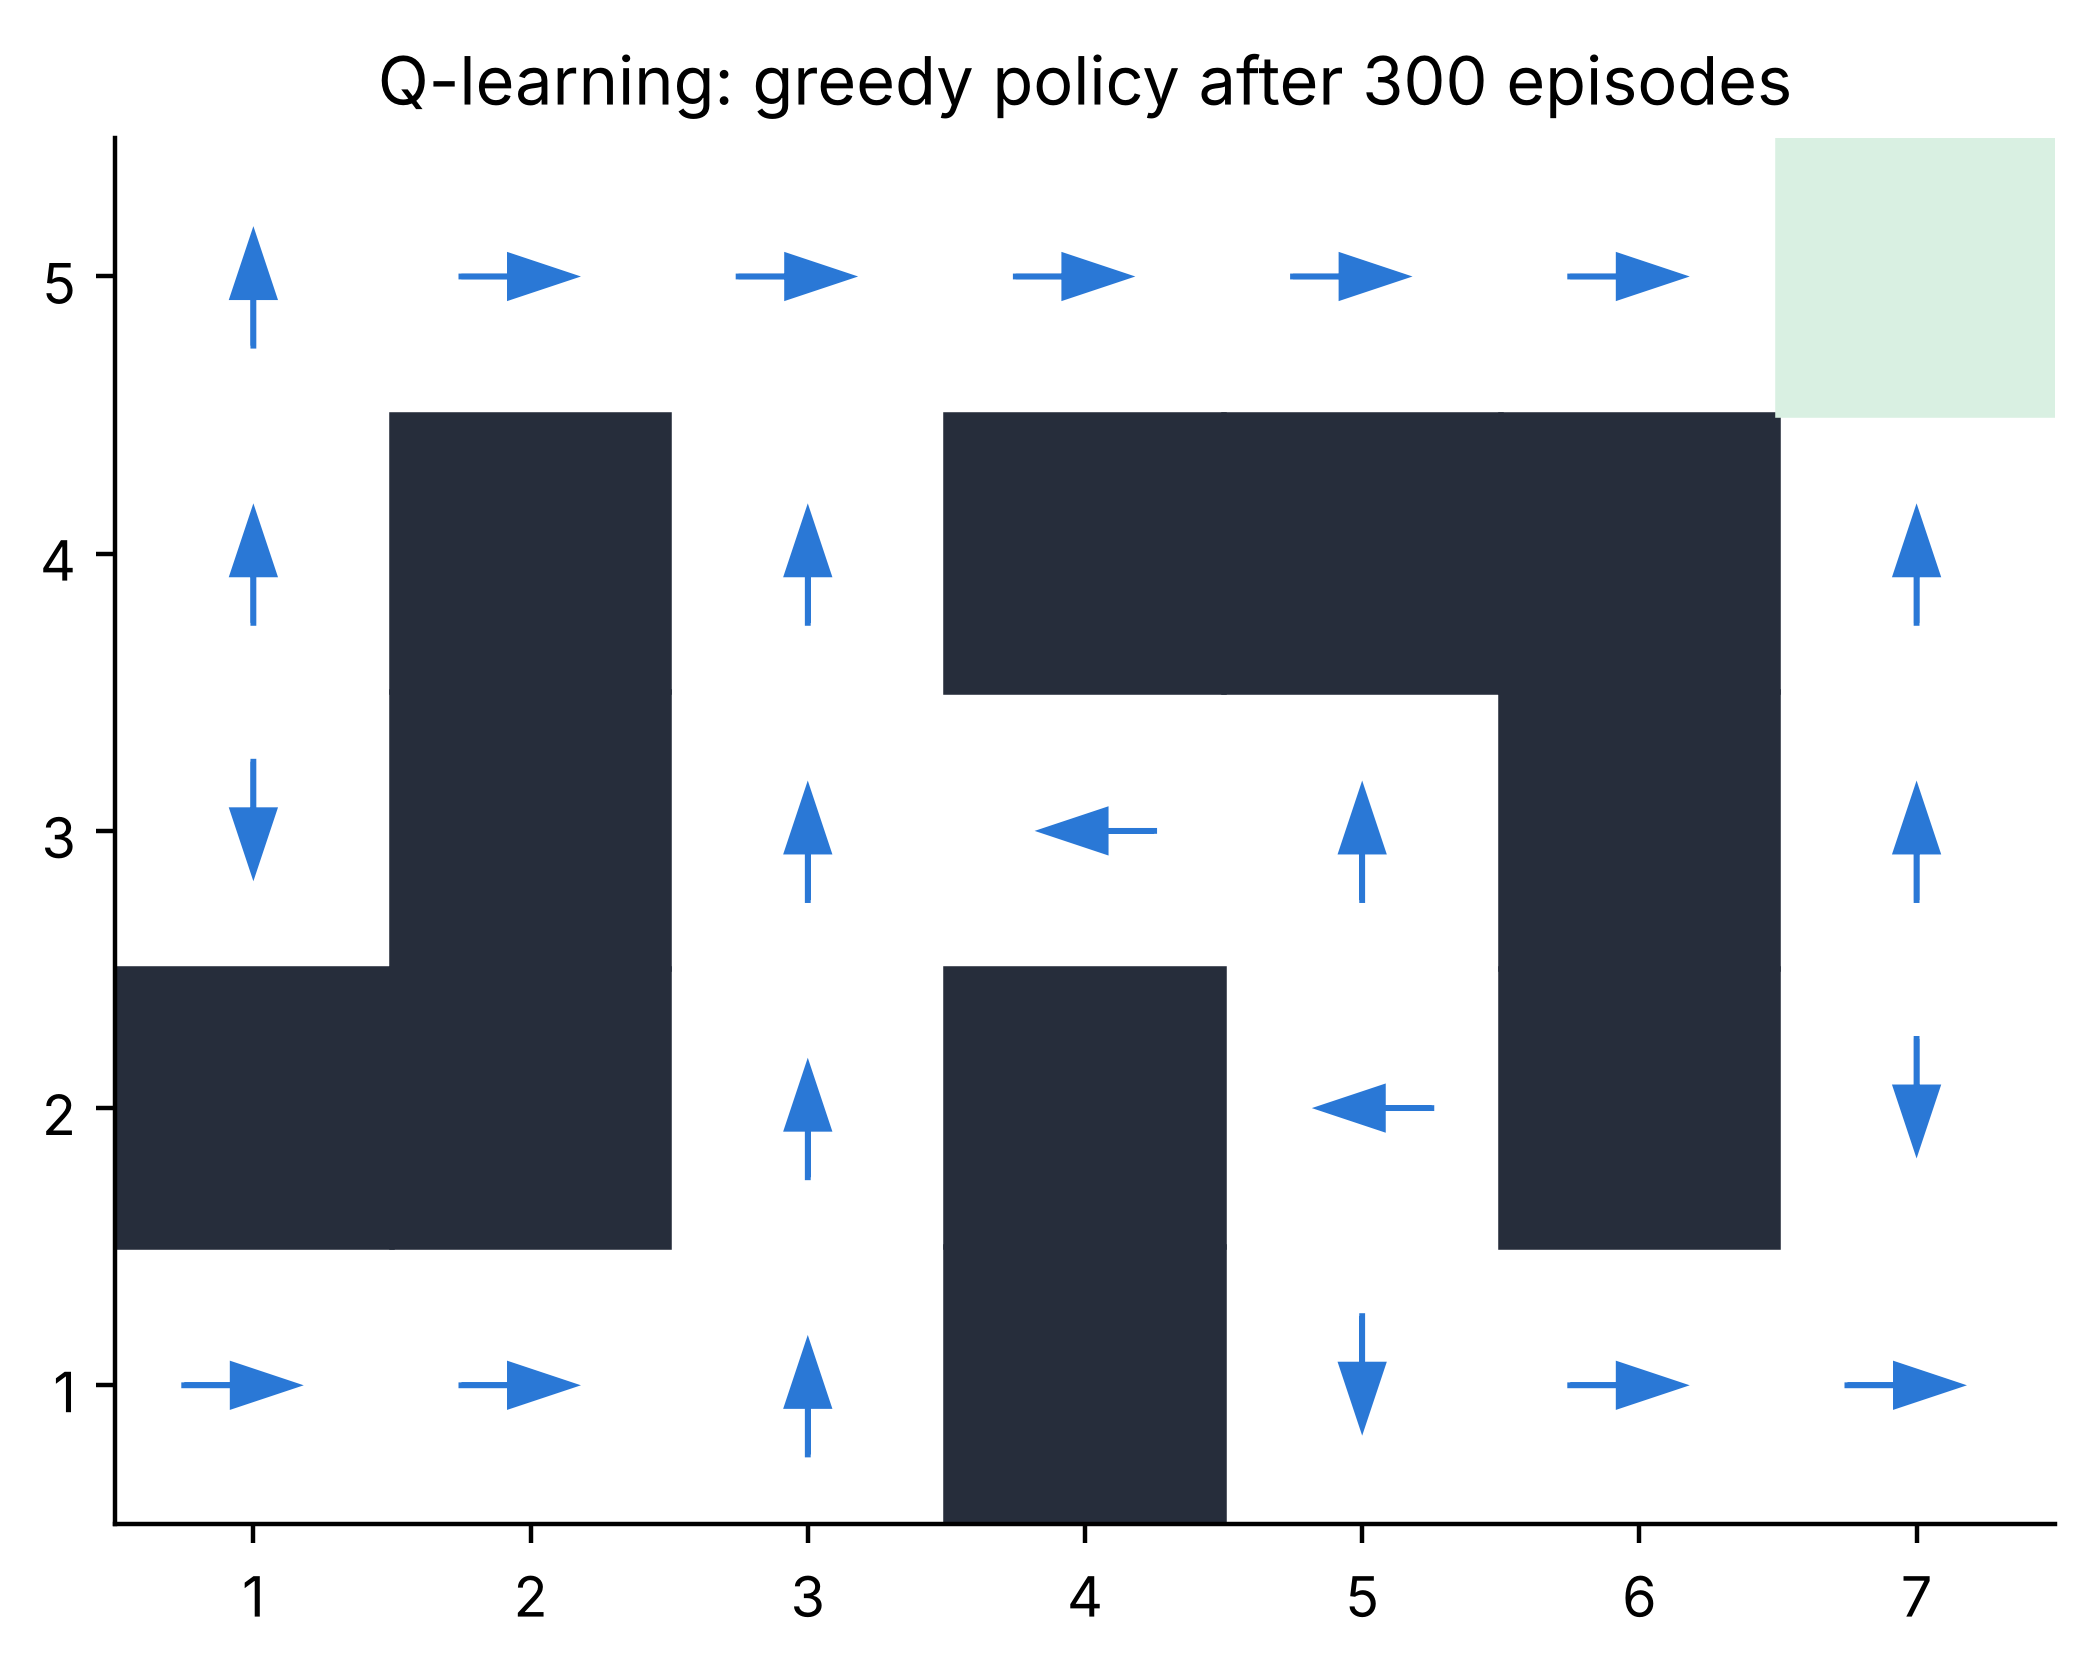

Q at the start square (up, down, left, right): [-4.4  -4.38 -4.43 -4.33]


In [8]:
def plot_policy(env, Q, title):
    fig, ax = plt.subplots(figsize=(env.width * 0.9, env.height * 0.9))
    for (c, r), q in Q.items():
        if (c, r) in env.walls:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color="#262d3b")); continue
        if (c, r) == env.target:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color="#d9f0e2")); continue
        dc, dr = Maze.MOVES[int(q.argmax())]
        ax.arrow(c - 0.25 * dc, r - 0.25 * dr, 0.4 * dc, 0.4 * dr, head_width=0.15, color="#2a78d6", length_includes_head=True)
    ax.set_xlim(0.5, env.width + 0.5); ax.set_ylim(0.5, env.height + 0.5); ax.set_aspect("equal")
    ax.set_xticks(range(1, env.width + 1)); ax.set_yticks(range(1, env.height + 1)); ax.grid(False)
    ax.set_title(title); plt.show()

Q, _ = q_learning(small, seed=1)
plot_policy(small, Q, "Q-learning: greedy policy after 300 episodes")
print("Q at the start square (up, down, left, right):", np.round(Q[(1, 1)], 2))

**Line by line**

1. `def plot_policy(env, Q, title):`  
   Draw the walls, the target and an arrow per square.
2. `fig, ax = plt.subplots(figsize=(env.width * 0.9, env.height * 0.9))`  
   One inch per square, roughly.
3. `for (c, r), q in Q.items():`  
   Visit every square.
4. `if (c, r) in env.walls:` …  
   Walls: dark squares.
5. `if (c, r) == env.target:` …  
   The goal square.
6. `dc, dr = Maze.MOVES[int(q.argmax())]` …  
   The direction of the best action.
7. `ax.set_xlim(0.5, env.width + 0.5); ax.set_ylim(0.5, env.height + 0.5); ax.set_aspect("equal")`  
   Square cells.
8. `ax.set_xticks(range(1, env.width + 1)); ax.set_yticks(range(1, env.height + 1)); ax.grid(False)` …  
   Column and row numbers.
9. `Q, _ = q_learning(small, seed=1)`  
   One run of Q-learning.
10. `plot_policy(small, Q, "Q-learning: greedy policy after 300 episodes")`  
   Follow the arrows from (1,1): right, up the middle corridor, then along the top to the goal.
11. `print("Q at the start square (up, down, left, right):", np.round(Q[(1, 1)], 2))`  
   The best value is about −4.3: nine steps of −1, discounted.

## 9. The big maze

Shortest route 20 moves, episodes cut off at 60 steps. A random walk almost never reaches the goal, so Monte Carlo has nothing to learn from. Q-learning learns from every step.

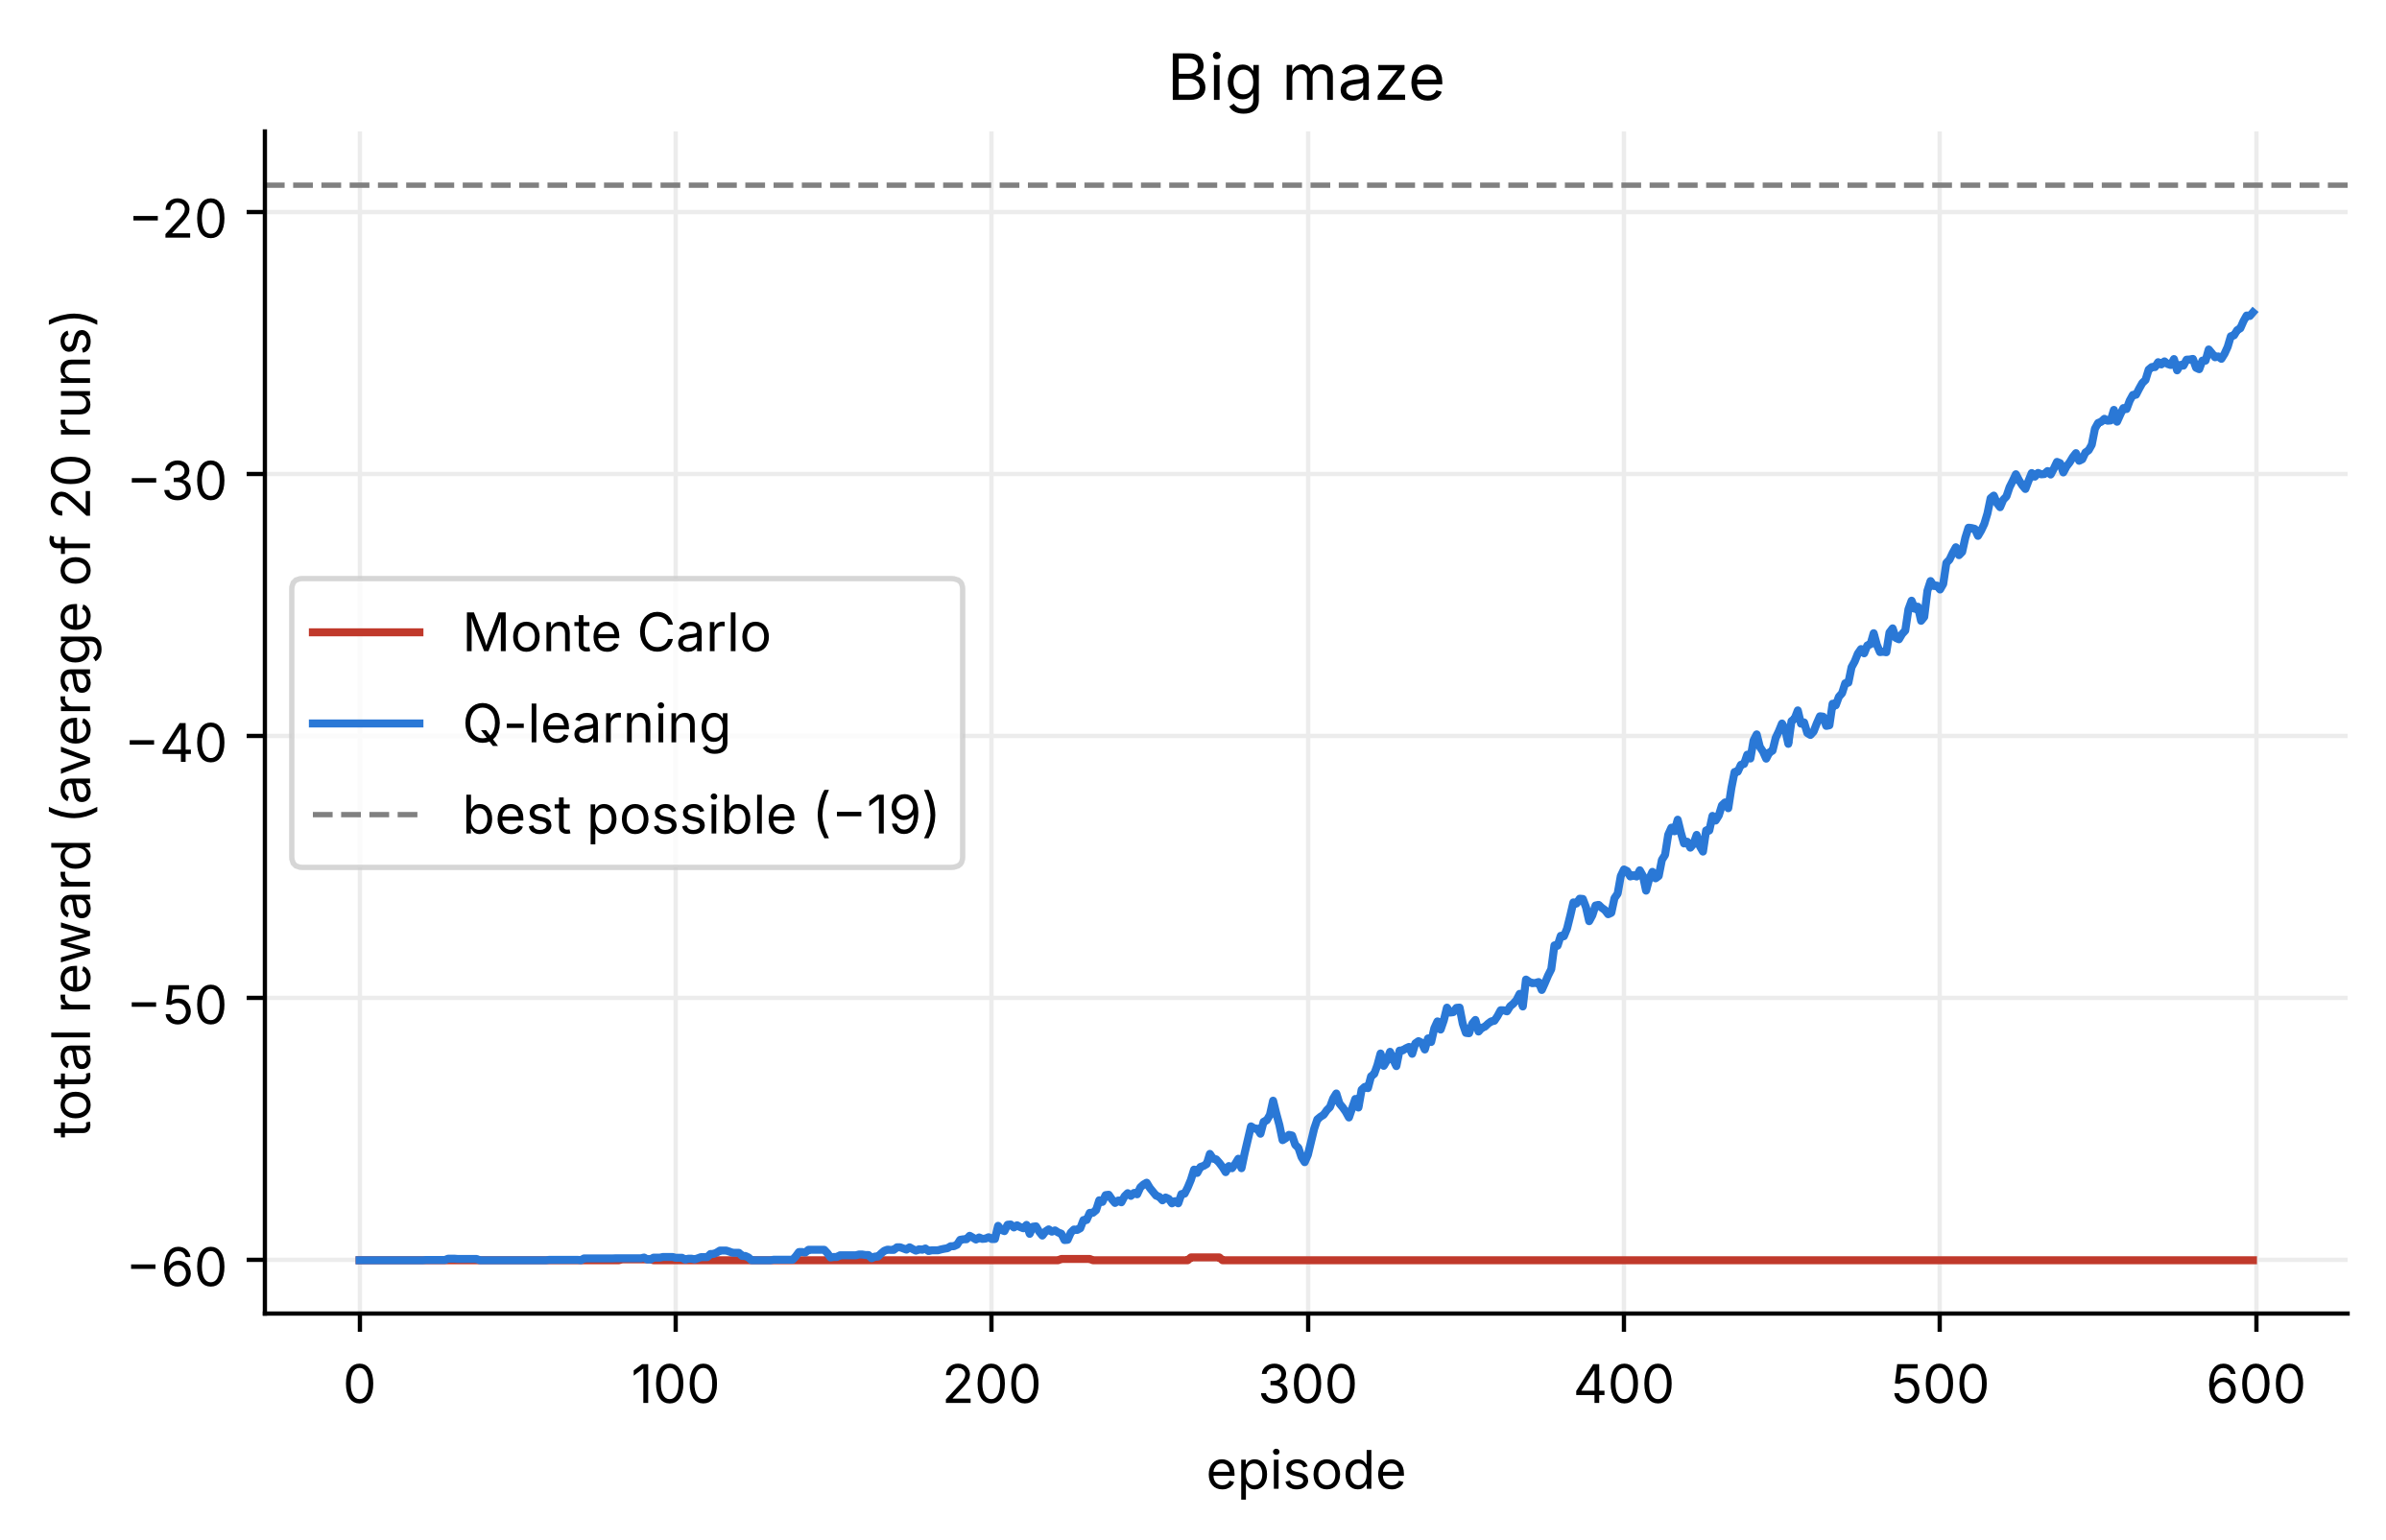

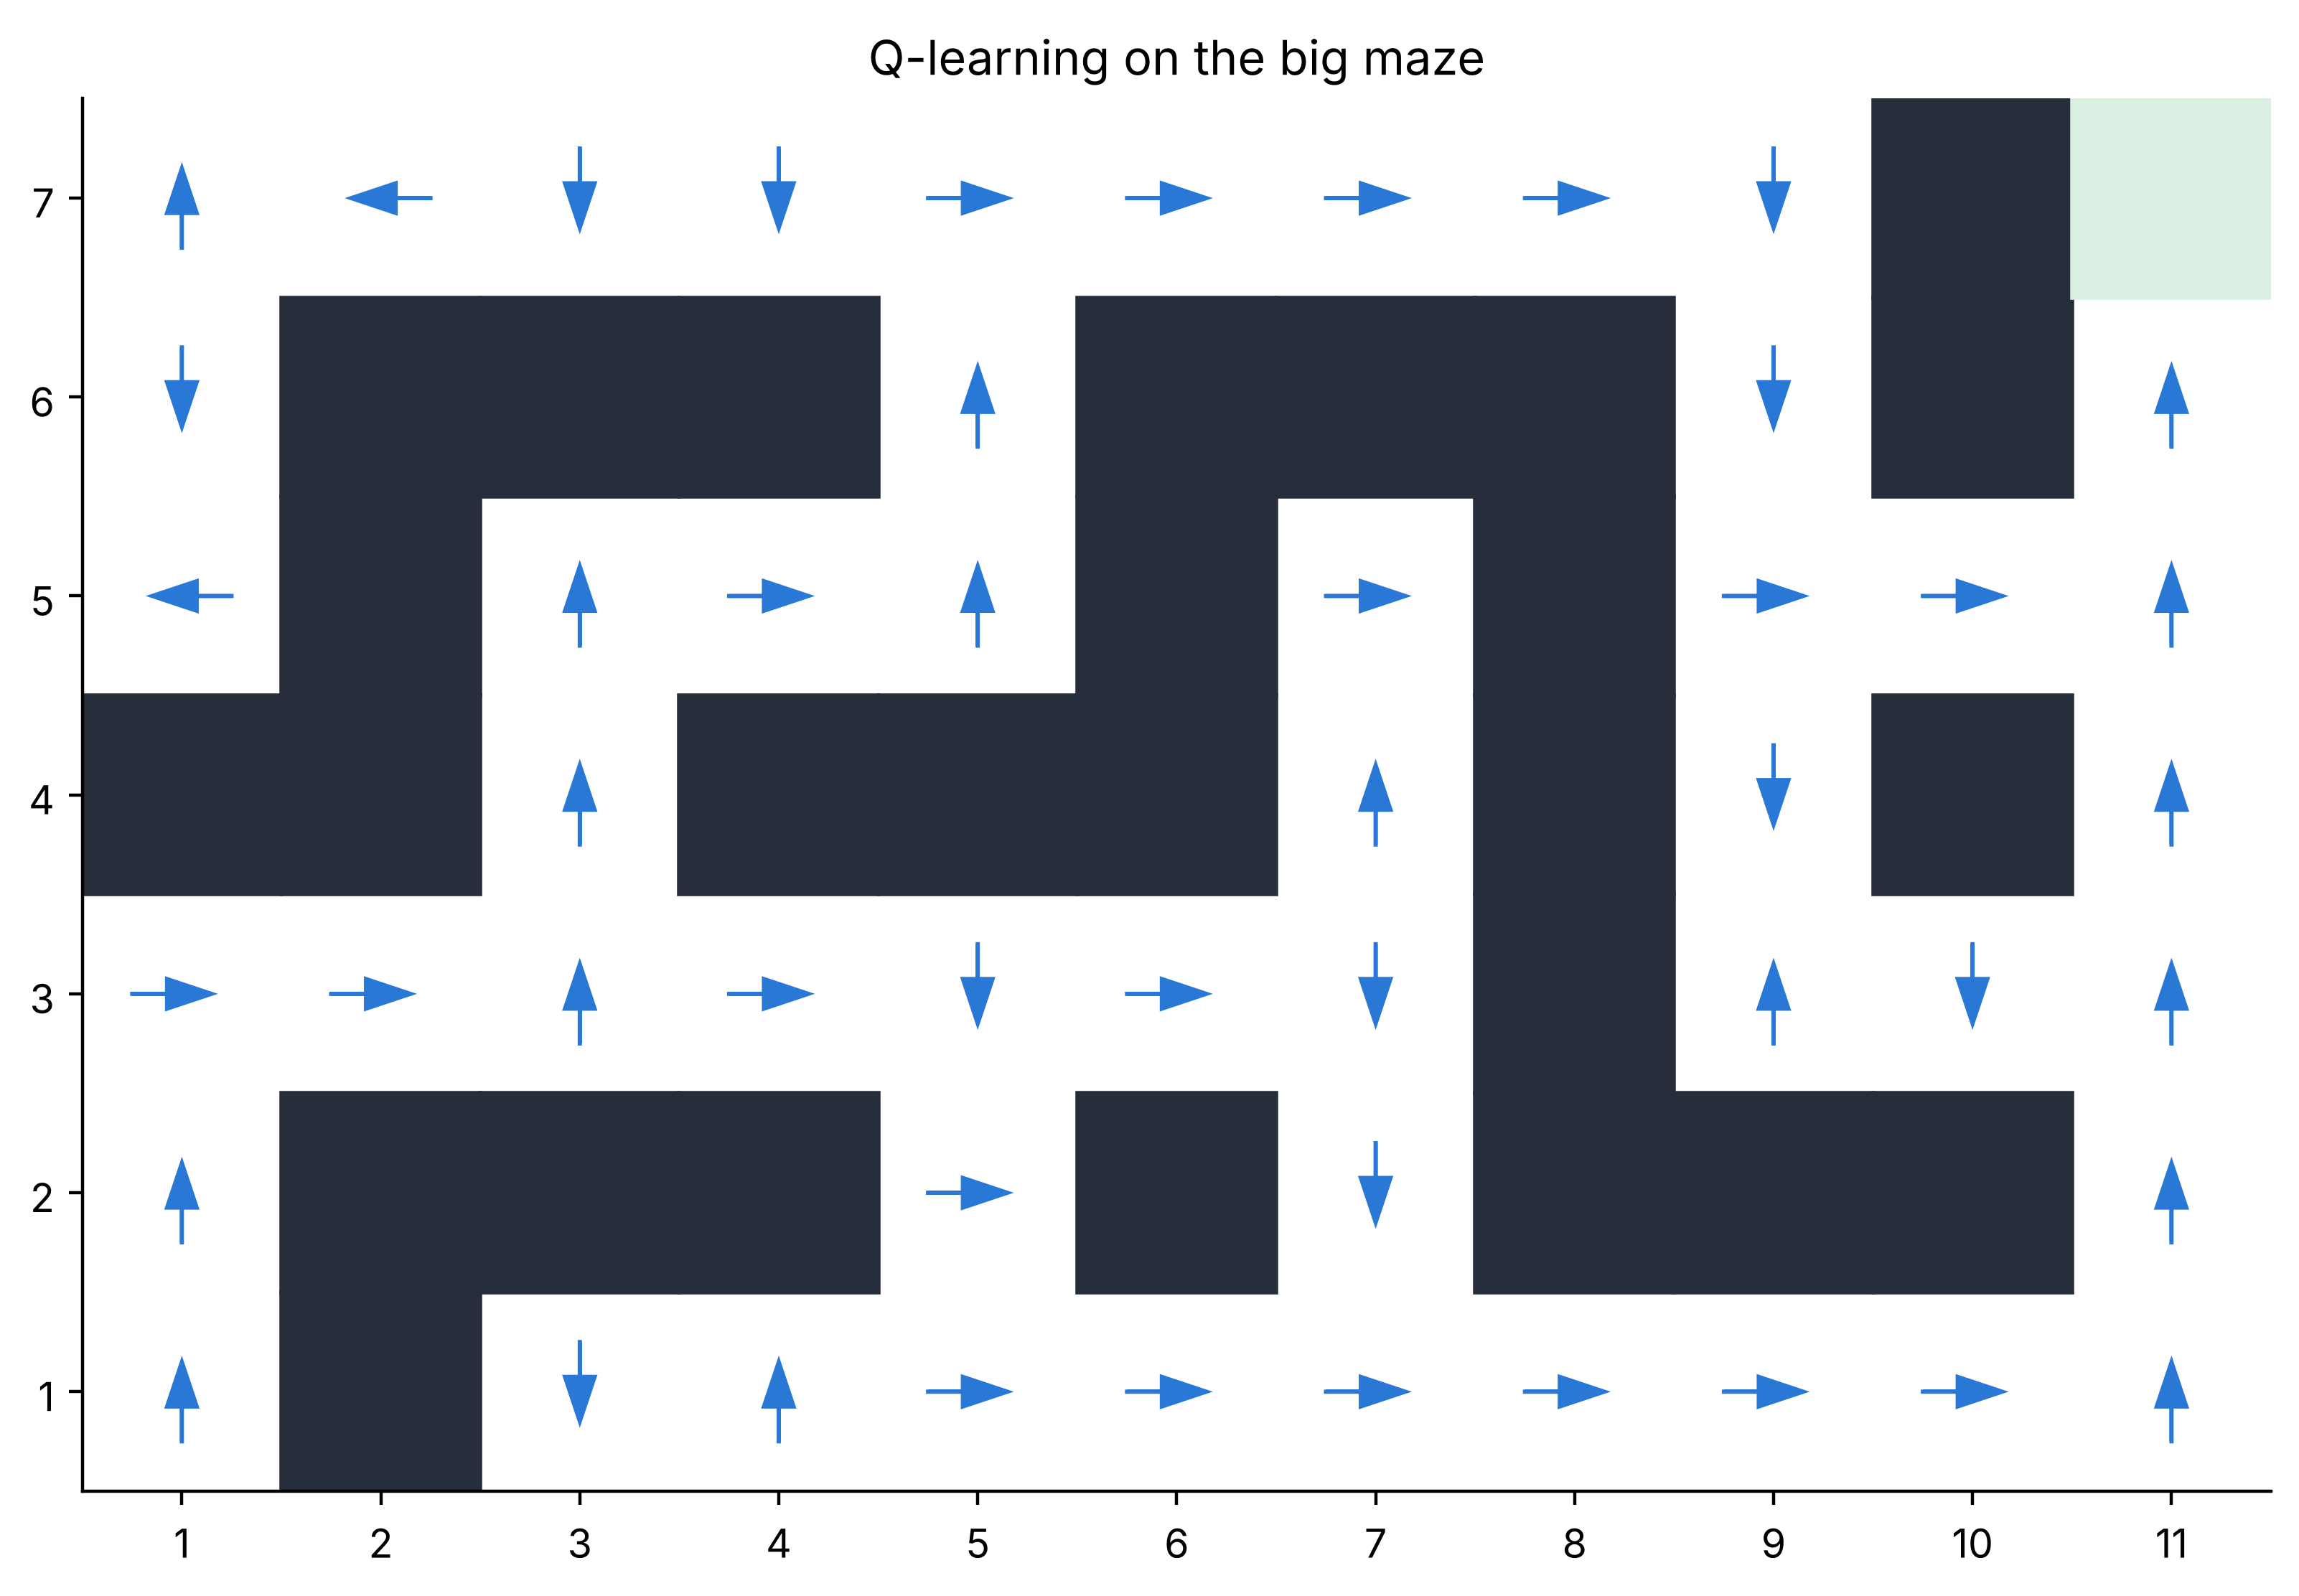

In [9]:
mc_big = average_curve(monte_carlo, big, runs=20, episodes=600)
ql_big = average_curve(q_learning, big, runs=20, episodes=600)
plt.plot(smooth(mc_big), color="#c0392b", label="Monte Carlo")
plt.plot(smooth(ql_big), color="#2a78d6", label="Q-learning")
plt.axhline(-19, ls="--", color="grey", lw=1, label="best possible (−19)")
plt.xlabel("episode"); plt.ylabel("total reward (average of 20 runs)"); plt.legend(); plt.title("Big maze")
plt.show()
Q_big, _ = q_learning(big, episodes=600, seed=3)
plot_policy(big, Q_big, "Q-learning on the big maze")

**Line by line**

1. `mc_big = average_curve(monte_carlo, big, runs=20, episodes=600)` …  
   20 runs of 600 episodes each.
2. `plt.show()`  
   Monte Carlo stays at −60: it never reaches the target.
3. `Q_big, _ = q_learning(big, episodes=600, seed=3)`  
   One Q-learning run on the big maze…
4. `plot_policy(big, Q_big, "Q-learning on the big maze")`  
   …and its greedy policy.

## 10. Try it yourself

1. Change `q_learning` into **SARSA**: choose the next action `a2` with `epsilon_greedy` *before* the update and use `Q[s2][a2]` instead of `Q[s2].max()`. Then really take `a2` in the next step.
2. Write **Expected SARSA**: replace the max by the average of `Q[s2]` weighted by the ε-greedy probabilities (the best action gets 1 − ε + ε/4).
3. Add a wall to `small` and see how the learned policy changes.
4. Try γ = 0.5 and γ = 0.99. What happens to the learning curves, and why?
5. Change the rewards in `step`: +10 at the goal and 0 per move with γ = 1, then γ = 0.9. Which one still finds the shortest route, and why?